# Lab03: Dự báo chuỗi thời gian — PM2.5 theo ngày tại TP.HCM

Code lấy nguyên từ bài **Lab03 — Python cho Máy học** (`Lab03_3.ipynb`: Prophet + Auto Regression cửa sổ 7 ngày),
**chỉ đổi dữ liệu đầu vào**: thay `DailyDelhiClimateTrain.csv` (`meantemp`, `humidity`) bằng PM2.5 và độ ẩm của TP.HCM.

| Bài Lab gốc | Bản này |
|---|---|
| `meantemp` (nhiệt độ Delhi) | `pm2_5` (PM2.5 trung bình ngày TP.HCM, µg/m³) |
| `humidity` (biến phụ) | `relative_humidity_2m` (độ ẩm, %) |

> Bỏ dòng `%pip install` và `import yfinance` của bài gốc (không dùng tới). PM2.5 là số liệu mô hình CAMS, chưa phải số đo trạm.

In [1]:
# ===== BƯỚC CHUẨN BỊ (ô duy nhất được thêm vào so với bài Lab) =====
# Đổi dữ liệu đầu vào sang dữ liệu không khí TP.HCM của đồ án AirHCM.
# Nguồn: du_lieu/gio_cache.csv — Open-Meteo, số liệu THEO GIỜ tại trung tâm TP.HCM (10.7769, 106.7009):
#   PM2.5, PM10 (mô hình CAMS) + nhiệt độ, độ ẩm, gió, mưa, áp suất (ERA5).
# Gộp thành số liệu THEO NGÀY (mỗi dòng = 1 ngày) rồi lưu ./data/pm25_hcm_ngay.csv.
from pathlib import Path
import numpy as np
import pandas as pd

goc = Path.cwd()
while not (goc / 'du_lieu' / 'gio_cache.csv').exists() and goc.parent != goc:
    goc = goc.parent
gio = pd.read_csv(goc / 'du_lieu' / 'gio_cache.csv', parse_dates=['time'])

ngay = gio.set_index('time').resample('D').agg({
    'pm2_5': 'mean', 'pm10': 'mean',
    'temperature_2m': 'mean', 'relative_humidity_2m': 'mean', 'wind_speed_10m': 'mean',
    'precipitation': 'sum', 'surface_pressure': 'mean',
})
ngay = ngay.interpolate(limit=3).dropna()           # vài giờ đầu chuỗi CAMS bị thiếu
ngay['mua'] = np.where(ngay.index.month.isin(range(5, 12)), 'Y', 'N')   # Y = mùa mưa (5–11), N = mùa khô
ngay.index.name = 'date'

Path('data').mkdir(exist_ok=True)
ngay.round(2).to_csv('data/pm25_hcm_ngay.csv')
print(ngay.shape, ngay.index.min().date(), '→', ngay.index.max().date())
ngay.head()

(1529, 8) 2022-08-04 → 2026-10-10


,pm2_5,pm10,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure,mua
date,,,,,,,,
2022-08-04,22.682353,32.817647,26.916667,86.208333,7.033333,10.4,1006.875000,Y
2022-08-05,18.570833,26.891667,26.987500,85.458333,9.566667,10.6,1006.341667,Y
2022-08-06,18.629167,27.033333,25.925000,87.958333,9.070833,12.2,1005.979167,Y
2022-08-07,20.250000,29.616667,26.287500,87.125000,12.050000,23.0,1005.650000,Y
2022-08-08,24.429167,35.541667,25.629167,87.291667,9.866667,19.1,1005.912500,Y


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, GridSearchCV
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import logging
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)   # bớt dòng log của Prophet

Importing plotly failed. Interactive plots will not work.


In [3]:
df_pm = pd.read_csv('./data/pm25_hcm_ngay.csv', index_col = 0)
df_pm.head()

,pm2_5,pm10,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure,mua
date,,,,,,,,
2022-08-04,22.68,32.82,26.92,86.21,7.03,10.4,1006.88,Y
2022-08-05,18.57,26.89,26.99,85.46,9.57,10.6,1006.34,Y
2022-08-06,18.63,27.03,25.92,87.96,9.07,12.2,1005.98,Y
2022-08-07,20.25,29.62,26.29,87.12,12.05,23.0,1005.65,Y
2022-08-08,24.43,35.54,25.63,87.29,9.87,19.1,1005.91,Y


In [4]:
df_pm.index = pd.to_datetime(df_pm.index).date

In [5]:
df_pm.head()

,pm2_5,pm10,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure,mua
2022-08-04,22.68,32.82,26.92,86.21,7.03,10.4,1006.88,Y
2022-08-05,18.57,26.89,26.99,85.46,9.57,10.6,1006.34,Y
2022-08-06,18.63,27.03,25.92,87.96,9.07,12.2,1005.98,Y
2022-08-07,20.25,29.62,26.29,87.12,12.05,23.0,1005.65,Y
2022-08-08,24.43,35.54,25.63,87.29,9.87,19.1,1005.91,Y


# Prophet

In [6]:
ds = pd.DataFrame({
    'ds': df_pm.index.tolist(),
    'y': df_pm['pm2_5'].tolist()
})
ds.head()

,ds,y
0,2022-08-04,22.68
1,2022-08-05,18.57
2,2022-08-06,18.63
3,2022-08-07,20.25
4,2022-08-08,24.43


In [7]:
ds_train, ds_test = train_test_split(ds, shuffle=False)

In [8]:
ds.dtypes

ds     object
y     float64
dtype: object

In [9]:
ph = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
ph.fit(ds_train)

E:\duongadmin\OneDrive\Máy tính\projectcn\air_quality_project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


15:03:48 - cmdstanpy - INFO - Chain [1] start processing


15:03:48 - cmdstanpy - INFO - Chain [1] done processing


In [10]:
y_train_pred = ph.predict(ds_train[['ds']])
y_test_pred = ph.predict(ds_test[['ds']])

In [11]:
bang_prophet = pd.DataFrame([
    ['r2 score', r2_score(ds_train['y'], y_train_pred['yhat']), r2_score(ds_test['y'], y_test_pred['yhat'])],
    ['MSE', mean_squared_error(ds_train['y'], y_train_pred['yhat']), mean_squared_error(ds_test['y'], y_test_pred['yhat'])],
    ['MAE', mean_absolute_error(ds_train['y'], y_train_pred['yhat']), mean_absolute_error(ds_test['y'], y_test_pred['yhat'])],
],columns=['Metric', 'Train', 'Test'])
bang_prophet

,Metric,Train,Test
0,r2 score,0.379189,-1.274320
1,MSE,66.066972,277.872507
2,MAE,6.195867,15.056285


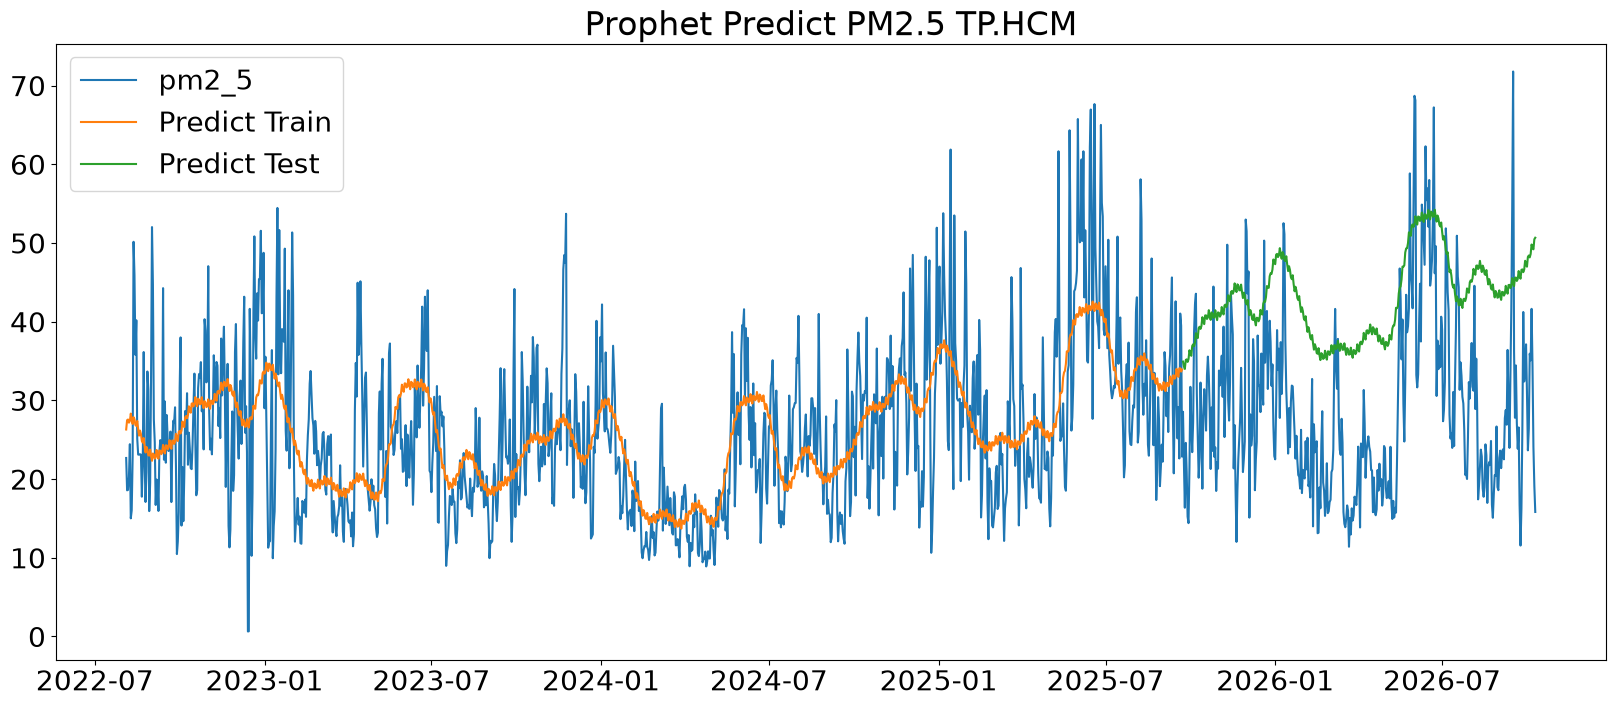

In [12]:
plt.rcParams['figure.figsize'] = (20, 8)
plt.rcParams['font.size'] = 20
plt.plot(ds['ds'], ds['y'])
plt.plot(ds_train['ds'], y_train_pred['yhat'])
plt.plot(ds_test['ds'], y_test_pred['yhat'])
plt.title('Prophet Predict PM2.5 TP.HCM')
plt.legend(['pm2_5', 'Predict Train', 'Predict Test'])
plt.show()

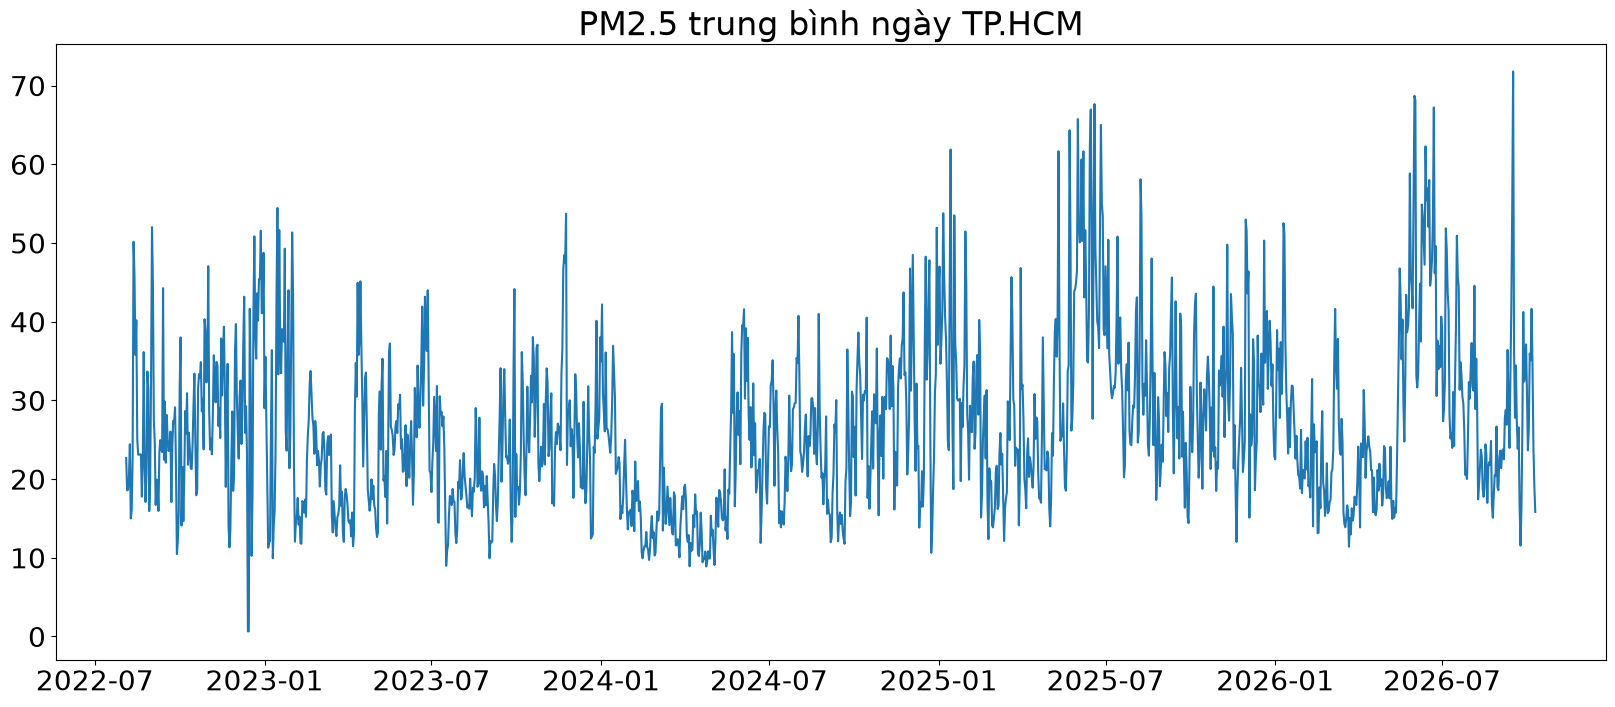

In [13]:
plt.rcParams['figure.figsize'] = (20, 8)
plt.rcParams['font.size'] = 20
plt.title('PM2.5 trung bình ngày TP.HCM')
plt.plot(df_pm['pm2_5'])
plt.show()

# Auto Regression

Dự báo PM2.5 ngày mai từ PM2.5 của **7 ngày trước** (cửa sổ trượt `widow_size = 7`).

In [14]:
widow_size = 7
n = df_pm.shape[0] -widow_size
data = {}
for i in range(widow_size):
    data[f'x_{i}'] = df_pm['pm2_5'].values[i: i + n]
data['y'] = df_pm['pm2_5'].values[widow_size:]
ds_pm = pd.DataFrame(data)
ds_pm.head()

,x_0,x_1,x_2,x_3,x_4,x_5,x_6,y
0,22.68,18.57,18.63,20.25,24.43,15.01,16.02,22.74
1,18.57,18.63,20.25,24.43,15.01,16.02,22.74,50.15
2,18.63,20.25,24.43,15.01,16.02,22.74,50.15,45.91
3,20.25,24.43,15.01,16.02,22.74,50.15,45.91,35.79
4,24.43,15.01,16.02,22.74,50.15,45.91,35.79,40.18


In [15]:
X = ds_pm.drop(columns='y')
y = ds_pm['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle = False)

In [16]:
lg = LinearRegression()
lg.fit(X_train, y_train)
lg.score(X_train, y_train), lg.score(X_test, y_test)

(0.5507597152636236, 0.5763508562162885)

In [17]:
y_train_pred = lg.predict(X_train)
y_test_pred = lg.predict(X_test)

In [18]:
df_pm['predict_train'] = [np.nan] * widow_size + y_train_pred.tolist() + [np.nan] * len(y_test_pred)
df_pm['predict_test'] = [np.nan] * (widow_size + len(y_train_pred)) + y_test_pred.tolist()

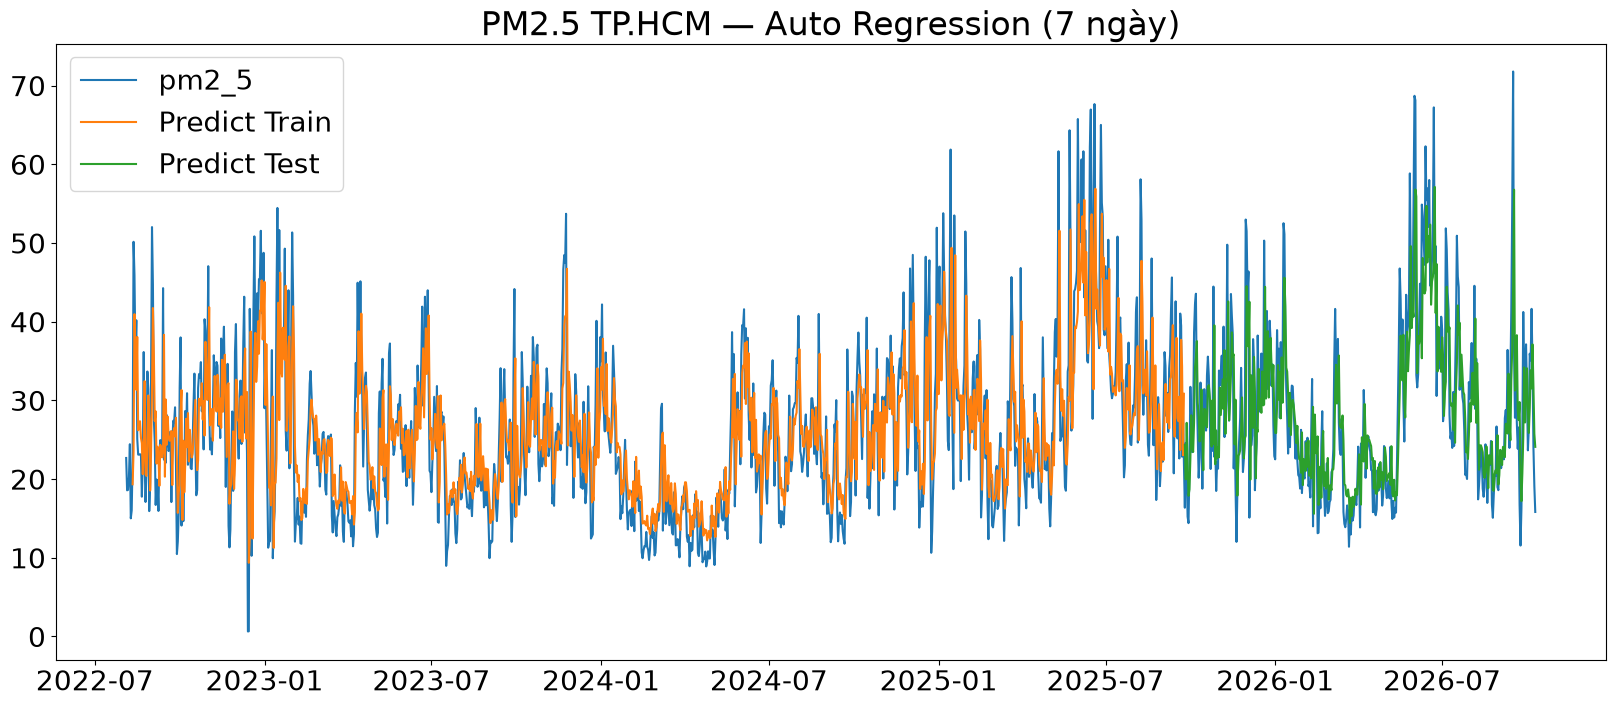

In [19]:
plt.rcParams['figure.figsize'] = (20, 8)
plt.rcParams['font.size'] = 20
plt.title('PM2.5 TP.HCM — Auto Regression (7 ngày)')
plt.plot(df_pm['pm2_5'])
plt.plot(df_pm['predict_train'])
plt.plot(df_pm['predict_test'])
plt.legend(['pm2_5', 'Predict Train', 'Predict Test'])
plt.show()

# Auto Regression nhiều biến: PM2.5 + độ ẩm

In [20]:
df= pd.read_csv('./data/pm25_hcm_ngay.csv',index_col=0).drop(columns='mua')   # bỏ cột chữ 'mua' để nội suy được
df.head()

,pm2_5,pm10,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure
date,,,,,,,
2022-08-04,22.68,32.82,26.92,86.21,7.03,10.4,1006.88
2022-08-05,18.57,26.89,26.99,85.46,9.57,10.6,1006.34
2022-08-06,18.63,27.03,25.92,87.96,9.07,12.2,1005.98
2022-08-07,20.25,29.62,26.29,87.12,12.05,23.0,1005.65
2022-08-08,24.43,35.54,25.63,87.29,9.87,19.1,1005.91


In [21]:
df.interpolate(method= 'linear', inplace=True)

,pm2_5,pm10,temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation,surface_pressure
date,,,,,,,
2022-08-04,22.68,32.82,26.92,86.21,7.03,10.4,1006.88
2022-08-05,18.57,26.89,26.99,85.46,9.57,10.6,1006.34
2022-08-06,18.63,27.03,25.92,87.96,9.07,12.2,1005.98
2022-08-07,20.25,29.62,26.29,87.12,12.05,23.0,1005.65
2022-08-08,24.43,35.54,25.63,87.29,9.87,19.1,1005.91
...,...,...,...,...,...,...,...
2026-10-06,41.63,42.02,27.30,86.88,4.85,19.7,1011.25
2026-10-07,34.43,34.50,27.60,85.42,5.21,15.5,1012.01
2026-10-08,24.09,24.39,26.94,85.83,7.19,13.0,1010.62


In [22]:
df.isna().sum()

pm2_5                   0
pm10                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
precipitation           0
surface_pressure        0
dtype: int64

In [23]:
widow_size = 7
n = df.shape[0] -widow_size
data = {}
for i in range(widow_size):
    data[F'xpm_{i}'] = df['pm2_5'].values[i: i + n]
    data[f'xhum_{i}'] = df['relative_humidity_2m'].values[i:i + n]
data['y'] = df['pm2_5'].values[widow_size:]
ds= pd.DataFrame(data)
ds.head()

,xpm_0,xhum_0,xpm_1,xhum_1,xpm_2,xhum_2,xpm_3,xhum_3,xpm_4,xhum_4,xpm_5,xhum_5,xpm_6,xhum_6,y
0,22.68,86.21,18.57,85.46,18.63,87.96,20.25,87.12,24.43,87.29,15.01,86.46,16.02,85.46,22.74
1,18.57,85.46,18.63,87.96,20.25,87.12,24.43,87.29,15.01,86.46,16.02,85.46,22.74,86.67,50.15
2,18.63,87.96,20.25,87.12,24.43,87.29,15.01,86.46,16.02,85.46,22.74,86.67,50.15,84.92,45.91
3,20.25,87.12,24.43,87.29,15.01,86.46,16.02,85.46,22.74,86.67,50.15,84.92,45.91,77.71,35.79
4,24.43,87.29,15.01,86.46,16.02,85.46,22.74,86.67,50.15,84.92,45.91,77.71,35.79,85.29,40.18


In [24]:
X = ds.drop(columns='y')
y = ds['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle = False)

In [25]:
lg = LinearRegression()
lg.fit(X_train, y_train)
lg.score(X_train, y_train), lg.score(X_test, y_test)

(0.5559423182232456, 0.5801064538519087)

In [26]:
y_train_pred = lg.predict(X_train)
y_test_pred = lg.predict(X_test)

In [27]:
df['train_pred'] = [np.nan] * widow_size + y_train_pred.tolist() + [np.nan] * len(y_test_pred)
df['test_pred'] = [np.nan] * (widow_size + len(y_train_pred)) + y_test_pred.tolist()

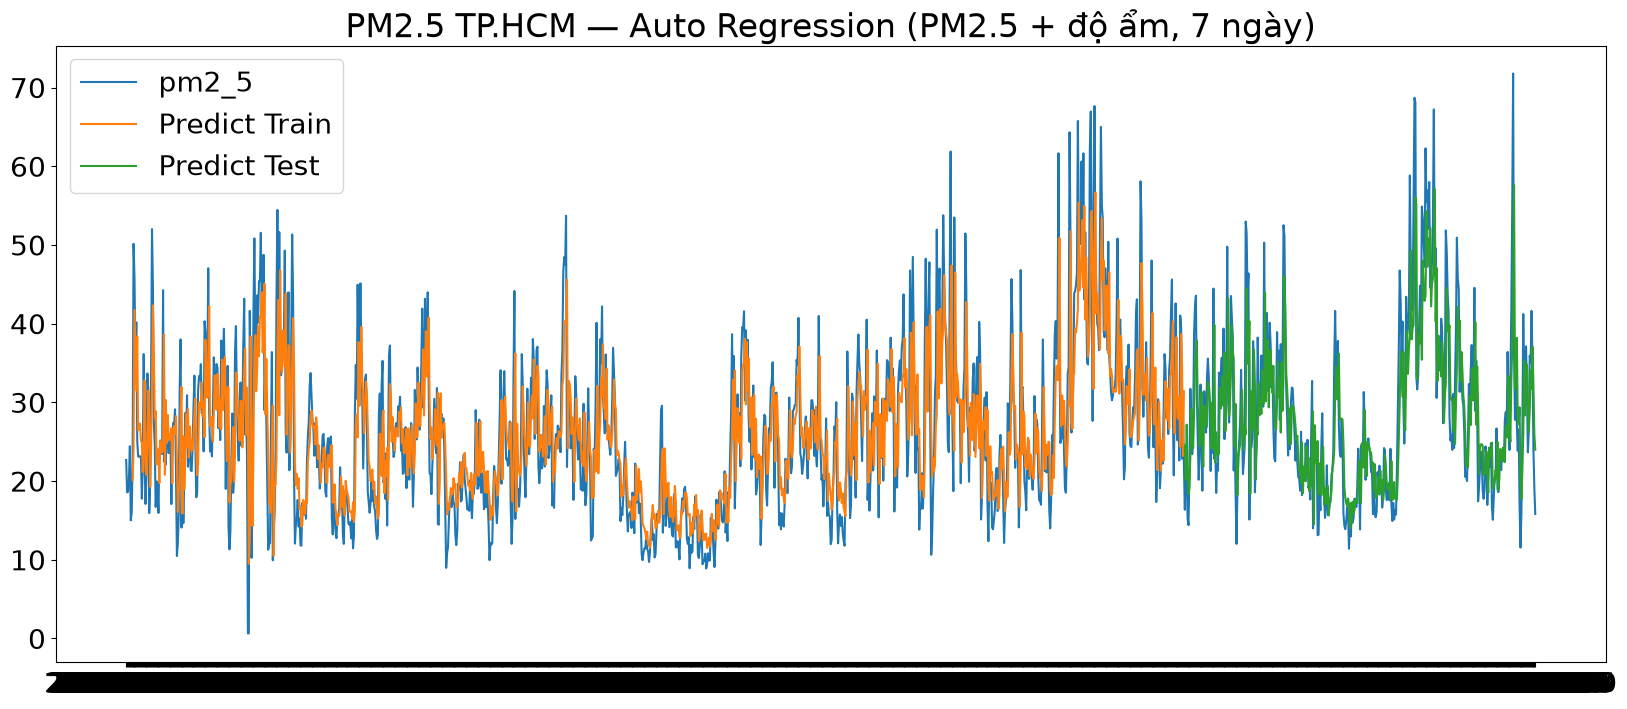

In [28]:
plt.rcParams['figure.figsize'] = (20, 8)
plt.rcParams['font.size'] = 20
plt.title('PM2.5 TP.HCM — Auto Regression (PM2.5 + độ ẩm, 7 ngày)')
plt.plot(df['pm2_5'])
plt.plot(df['train_pred'])
plt.plot(df['test_pred'])
plt.legend(['pm2_5', 'Predict Train', 'Predict Test'])
plt.show()

# Bổ sung: so với mô hình nền "ngày mai = hôm nay"

Ô này **thêm mới** để đánh giá trung thực: một mô hình dự báo chỉ có ích khi sai số nhỏ hơn cách đoán đơn giản nhất
là lấy luôn PM2.5 hôm nay làm dự báo cho ngày mai (*persistence*). Cùng tập test (25% cuối chuỗi).

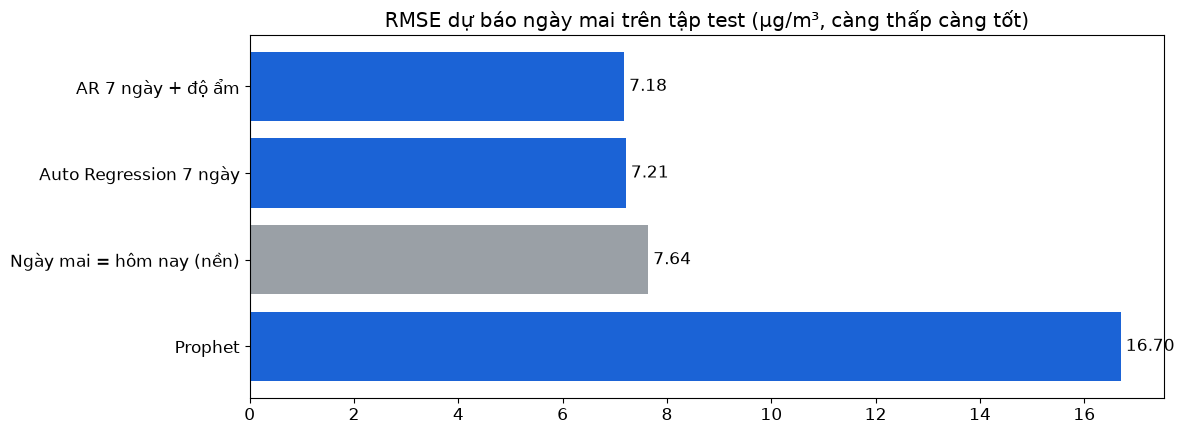

,model,MAE,RMSE,R2,Kỹ năng so với nền
0,Ngày mai = hôm nay (nền),5.562,7.639,0.524,0.000
1,Prophet,15.086,16.698,-1.273,-1.186
2,Auto Regression 7 ngày,5.328,7.210,0.576,0.056
3,AR 7 ngày + độ ẩm,5.287,7.178,0.580,0.060


In [29]:
y_that = df['pm2_5'].values[widow_size:][len(y_train_pred):]
nen = df['pm2_5'].values[widow_size - 1:-1][len(y_train_pred):]          # giá trị hôm trước
ar1 = df_pm['predict_test'].dropna().values
ar2 = df['test_pred'].dropna().values
prophet_test = ph.predict(ds_test[['ds']])['yhat'].values[-len(y_that):]

def chi_so(ten, du):
    return {'model': ten, 'MAE': mean_absolute_error(y_that, du),
            'RMSE': float(np.sqrt(mean_squared_error(y_that, du))), 'R2': r2_score(y_that, du)}

df_ss = pd.DataFrame([
    chi_so('Ngày mai = hôm nay (nền)', nen),
    chi_so('Prophet', prophet_test),
    chi_so('Auto Regression 7 ngày', ar1),
    chi_so('AR 7 ngày + độ ẩm', ar2),
])
df_ss['Kỹ năng so với nền'] = 1 - df_ss['RMSE'] / df_ss.loc[0, 'RMSE']
plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['font.size'] = 12
dv = df_ss.sort_values('RMSE', ascending=False)
mau = ['#9aa0a6' if 'nền' in m else '#1b63d6' for m in dv['model']]
plt.barh(dv['model'], dv['RMSE'], color=mau)
for i, v in enumerate(dv['RMSE']):
    plt.text(v, i, f' {v:.2f}', va='center')
plt.title('RMSE dự báo ngày mai trên tập test (µg/m³, càng thấp càng tốt)')
plt.tight_layout()
plt.show()

import json
Path('ket_qua').mkdir(exist_ok=True)
json.dump({'so_ngay_test': int(len(y_that)), 'mo_hinh': df_ss.round(4).to_dict('records')},
          open('ket_qua/lab03_chi_so.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
df_ss.round(3)

### Kết luận

1. **Prophet** bắt được chu kỳ năm trên tập train (R² train = 0.38) nhưng **dự báo test rất kém** (R² = −1.27, MAE = 15.1 µg/m³):
   tập train kết thúc vào giai đoạn PM2.5 cao bất thường năm 2025 (trung vị cả năm 30.0 so với 21–26 các năm khác),
   nên Prophet ngoại suy xu hướng tăng lên, trong khi năm 2026 PM2.5 giảm lại.
2. **Auto Regression 7 ngày** đạt R² test = 0.576, RMSE = 7.21 µg/m³; thêm độ ẩm 7 ngày trước nhích lên R² = 0.580, RMSE = 7.18.
3. **So với nền "ngày mai = hôm nay"** (RMSE = 7.64): tự hồi quy chỉ tốt hơn **≈ 6%**. Nghĩa là PM2.5 ngày mai phụ thuộc chủ yếu vào hôm nay;
   mô hình theo ngày chỉ nhỉnh hơn cách đoán đơn giản nhất — khớp với đánh giá ở trang Phương pháp của hệ thống
   (dự báo **theo giờ** mới có kỹ năng rõ rệt).